<a href="https://colab.research.google.com/github/samrat-dhakal-11/machine_learning/blob/main/first_end_to_end_ml_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Steps to do

In [88]:
# Steps

# 0. Preprocess + EDA + Feature Selection
# 1. Extract input and output cols
# 2. Scale the values
# 3. Train test split
# 4. Train the model
# 5. Evaluate the model/model selection


Code

In [89]:
import numpy as np
import pandas as pd

In [90]:
df=pd.read_csv('/content/placement.csv')

In [91]:
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [92]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB


In [93]:
df = df.iloc[:, 1:]

In [94]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


Text(0, 0.5, 'iq')

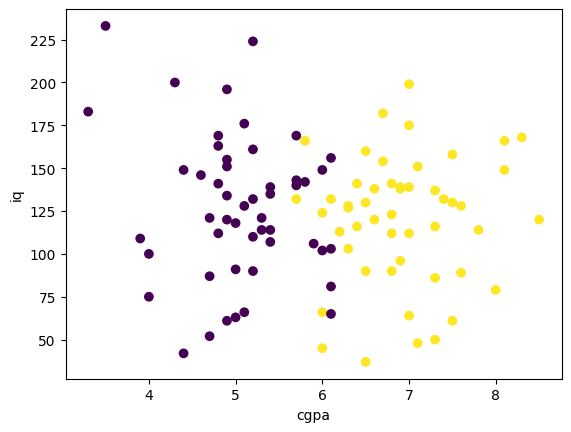

In [95]:
import matplotlib.pyplot as plt

plt.scatter(df['cgpa'],df['iq'],c=df['placement'])
plt.xlabel('cgpa')
plt.ylabel('iq')

In [96]:
X=df.iloc[:,0:2]
Y=df.iloc[:,-1]

In [97]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.1)

In [98]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

In [99]:
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [100]:
from sklearn.linear_model import LogisticRegression

model=LogisticRegression()

In [101]:
# model tranning

model.fit(x_train,y_train)

LogisticRegression()

In [102]:
y_pred=model.predict(x_test)

In [103]:
y_test


,placement
14,0
72,1
86,0
11,1
68,0
38,1
13,1
62,0
40,0
64,1


In [104]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.8

Text(0, 0.5, 'iq (scaled)')

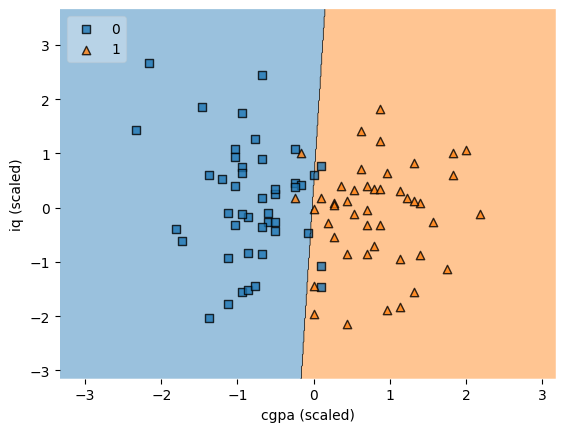

In [105]:
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(x_train,y_train.values,clf=model,legend=2)
plt.xlabel('cgpa (scaled)')
plt.ylabel('iq (scaled)')

In [106]:
import pickle

In [107]:
pickle.dump(model,open('model.pkl','wb'))